# Выполнение задания по проекту прогнозирования стоимости недвижимости

## Загрузка тестовых данных

In [2]:
import pandas as pd
import numpy as np
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
test_df = pd.read_csv('test_real_estate_samples.csv')

In [4]:
test_df.shape

(20, 17)

In [5]:
test_df.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,2+2,250.0,İzmir/Foça/Yeniköy,NaN,Yok,1600000.0,TRY
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,3+1,122.0,Tekirdağ/Çerkezköy/Kızılpınar,NaN,Yok,103600.0,TRY
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY


In [6]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 20 non-null     int64  
 1   type               20 non-null     object 
 2   sub_type           20 non-null     object 
 3   start_date         20 non-null     object 
 4   end_date           13 non-null     object 
 5   listing_type       20 non-null     int64  
 6   tom                20 non-null     int64  
 7   building_age       16 non-null     object 
 8   total_floor_count  20 non-null     object 
 9   floor_no           12 non-null     object 
 10  room_count         20 non-null     object 
 11  size               17 non-null     float64
 12  address            20 non-null     object 
 13  furnished          0 non-null      float64
 14  heating_type       20 non-null     object 
 15  price              20 non-null     float64
 16  price_currency     20 non-nu

In [7]:
test_df.describe()

,id,listing_type,tom,size,furnished,price
count,20.000000,20.000000,20.000000,17.000000,0.0,2.000000e+01
mean,5257.250000,1.500000,55.200000,165.588235,NaN,3.808350e+05
std,20427.688748,0.512989,41.912942,201.806857,NaN,6.403123e+05
min,1.000000,1.000000,0.000000,1.000000,NaN,7.500000e+02
25%,14.750000,1.000000,30.000000,85.000000,NaN,3.712500e+03
50%,104.500000,1.500000,38.000000,125.000000,NaN,6.130000e+04
75%,566.000000,2.000000,92.500000,160.000000,NaN,4.925000e+05
max,91731.000000,2.000000,152.000000,905.000000,NaN,2.450000e+06


## Загрузка сохранённой модели и препроцессоров

In [8]:
SAVE_DIR = r"C:\Users\Liliann\Desktop\College\МОиБД\ml_projects"

In [9]:
# Загружаем модель
best_model = joblib.load(os.path.join(SAVE_DIR, 'best_model.pkl'))
print("Модель загружена:", type(best_model).__name__)

Модель загружена: RandomForestRegressor


In [10]:
# Загружаем скалер
scaler = joblib.load(os.path.join(SAVE_DIR, 'scaler.pkl'))
print("Scaler загружен:", type(scaler).__name__)

Scaler загружен: RobustScaler


In [11]:
# Загружаем импутер
imputer = joblib.load(os.path.join(SAVE_DIR, 'imputer.pkl'))
print("Imputer загружен:", type(imputer).__name__)

Imputer загружен: SimpleImputer


In [12]:
# Загружаем список признаков
feature_names = joblib.load(os.path.join(SAVE_DIR, 'feature_names.pkl'))
print("Количество признаков:", len(feature_names))
print("Признаки", feature_names)

Количество признаков: 102
Признаки ['size', 'rooms', 'living_rooms', 'building_age_num', 'total_floors_num', 'is_penthouse', 'is_garden', 'is_ground', 'floor_num', 'sub_type_grouped_Müstakil Ev', 'sub_type_grouped_Other', 'sub_type_grouped_Rezidans', 'sub_type_grouped_Villa', 'sub_type_grouped_Yazlık', 'heating_grouped_Klima', 'heating_grouped_Kombi (Doğalgaz)', 'heating_grouped_Merkezi Sistem', 'heating_grouped_Merkezi Sistem (Isı Payı Ölçer)', 'heating_grouped_Other', 'heating_grouped_Soba (Kömür)', 'city_Adıyaman', 'city_Afyonkarahisar', 'city_Aksaray', 'city_Amasya', 'city_Ankara', 'city_Antalya', 'city_Ardahan', 'city_Artvin', 'city_Aydın', 'city_Ağrı', 'city_Balıkesir', 'city_Bartın', 'city_Batman', 'city_Bayburt', 'city_Bilecik', 'city_Bingöl', 'city_Bitlis', 'city_Bolu', 'city_Burdur', 'city_Bursa', 'city_Denizli', 'city_Diyarbakır', 'city_Düzce', 'city_Edirne', 'city_Elazığ', 'city_Erzincan', 'city_Erzurum', 'city_Eskişehir', 'city_Gaziantep', 'city_Giresun', 'city_Gümüşhane',

## Предобработка тестовых данных

In [14]:
test_proc = test_df.copy()

In [15]:
test_proc.columns.tolist()


['id',
 'type',
 'sub_type',
 'start_date',
 'end_date',
 'listing_type',
 'tom',
 'building_age',
 'total_floor_count',
 'floor_no',
 'room_count',
 'size',
 'address',
 'furnished',
 'heating_type',
 'price',
 'price_currency']

In [16]:
y_test_real = test_proc['price'].copy()

In [17]:
y_test_real.shape

(20,)

In [18]:
is_sale = test_proc['listing_type'] == 1
is_try = test_proc['price_currency'] == 'TRY'
valid_for_metrics = is_sale & is_try
print(f"Объектов продажи в TRY: {valid_for_metrics.sum()} из {len(test_proc)}")

Объектов продажи в TRY: 10 из 20


In [19]:
test_proc = test_proc.drop(columns=['furnished'], errors='ignore')

In [20]:
test_proc = test_proc.drop(columns=['type'], errors='ignore')

## Feature Engineering

In [21]:
test_proc['city'] = test_proc['address'].str.split('/').str[0].str.strip()
test_proc['district'] = test_proc['address'].str.split('/').str[1].str.strip()
test_proc['district'] = test_proc['district'].fillna('Unknown')

In [22]:
test_proc['rooms'] = test_proc['room_count'].str.extract(r'^(\d+)').astype(float)
test_proc['living_rooms'] = test_proc['room_count'].str.extract(r'\+(\d+)').astype(float).fillna(0)

In [23]:
test_proc['building_age_num'] = test_proc['building_age'].str.extract(r'(\d+)').astype(float).fillna(10)

In [24]:
test_proc['total_floors_num'] = test_proc['total_floor_count'].str.extract(r'^(\d+)').astype(float).fillna(5)

In [25]:
test_proc['is_penthouse'] = test_proc['floor_no'].str.contains('Çatı|En Üst', na=False).astype(int)
test_proc['is_garden'] = test_proc['floor_no'].str.contains('Bahçe', na=False).astype(int)
test_proc['is_ground'] = test_proc['floor_no'].str.contains('Giriş|Zemin|Kot|Yüksek', na=False).astype(int)
test_proc['floor_num'] = test_proc['floor_no'].str.extract(r'^(\d+)').astype(float).fillna(0)

In [26]:
top_subtypes = ['Daire', 'Villa', 'Müstakil Ev', 'Rezidans', 'Yazlık']
test_proc['sub_type_grouped'] = test_proc['sub_type'].apply(
    lambda x: x if x in top_subtypes else 'Other'
)

In [27]:
top_heating = ['Kombi (Doğalgaz)', 'Klima', 'Merkezi Sistem (Isı Payı Ölçer)',
               'Merkezi Sistem', 'Kalorifer (Doğalgaz)', 'Soba (Kömür)']
test_proc['heating_grouped'] = test_proc['heating_type'].apply(
    lambda x: x if x in top_heating else 'Other'
)

### One-Hot Encoding

In [28]:
cols_to_encode = ['sub_type_grouped', 'heating_grouped', 'price_currency', 'city']
cols_to_encode = [c for c in cols_to_encode if c in test_proc.columns]
test_proc = pd.get_dummies(test_proc, columns=cols_to_encode, drop_first=True, dtype=int)

### Feature Engineering

In [29]:
test_proc['size_per_room'] = test_proc['size'] / (test_proc['rooms'] + 1)
test_proc['is_new_building'] = (test_proc['building_age_num'] <= 5).astype(int)
test_proc['floor_ratio'] = test_proc['floor_num'] / (test_proc['total_floors_num'] + 1)
test_proc['has_living_room'] = (test_proc['living_rooms'] > 0).astype(int)

In [30]:
cols_to_drop_final = ['address', 'room_count', 'building_age', 'total_floor_count',
                      'floor_no', 'sub_type', 'heating_type', 'start_date', 'end_date',
                      'listing_date', 'tom', 'district', 'id']
test_proc = test_proc.drop(columns=[c for c in cols_to_drop_final if c in test_proc.columns])

In [31]:
X_test_real = test_proc.reindex(columns=feature_names, fill_value=0)

In [32]:
print("Размер после выравнивания:", X_test_real.shape)

missing = set(feature_names) - set(test_proc.columns)
extra = set(test_proc.columns) - set(feature_names)
print(f"Пропущено в тесте: {len(missing)}")
print(f"Лишних в тесте: {len(extra)}")

Размер после выравнивания: (20, 102)
Пропущено в тесте: 73
Лишних в тесте: 2


In [33]:
X_test_imp = pd.DataFrame(imputer.transform(X_test_real), columns=X_test_real.columns)

In [34]:
X_test_scaled = scaler.transform(X_test_imp)

In [36]:
X_test_scaled.shape

(20, 102)

## Прогнозирование

In [37]:
y_pred_real = best_model.predict(X_test_scaled)
print("Прогнозы получены:", y_pred_real.shape)
print(y_pred_real)

Прогнозы получены: (20,)
[ 948402.5        1161262.5         771114.1341802   193314.32862384
  948402.5         184239.23919315  208380.61914302  170310.83803691
 1151157.7724359   451865.          339671.57871201  186435.01892597
  184194.09220304  359665.42633951  339999.16666667  985365.
  160181.52946214  242466.04305199  985365.          771114.1341802 ]


In [38]:
results_df = test_df.copy()
results_df['predicted_price'] = y_pred_real
results_df['actual_price'] = y_test_real.values
results_df['abs_error'] = np.abs(results_df['actual_price'] - results_df['predicted_price'])
results_df['error_percent'] = (results_df['abs_error'] / results_df['actual_price']) * 100

In [39]:
results_df[['id', 'sub_type', 'size', 'listing_type', 'price_currency',
            'actual_price', 'predicted_price', 'abs_error', 'error_percent']]

,id,sub_type,size,listing_type,price_currency,actual_price,predicted_price,abs_error,error_percent
0,49,Kooperatif,1.0,1,TRY,300000.0,9.484025e+05,6.484025e+05,216.134167
1,506,Çiftlik Evi,250.0,1,TRY,1600000.0,1.161262e+06,4.387375e+05,27.421094
2,2,Daire,43.0,1,TRY,490000.0,7.711141e+05,2.811141e+05,57.370231
3,528,Prefabrik Ev,122.0,1,TRY,103600.0,1.933143e+05,8.971433e+04,86.596842
4,109,Kooperatif,1.0,1,TRY,300000.0,9.484025e+05,6.484025e+05,216.134167
5,100,Yazlık,150.0,1,TRY,500000.0,1.842392e+05,3.157608e+05,63.152152
6,320,Yazlık,134.0,1,TRY,1000000.0,2.083806e+05,7.916194e+05,79.161938
7,3,Daire,NaN,1,TRY,155000.0,1.703108e+05,1.531084e+04,9.877960
8,7810,Loft,145.0,1,TRY,650000.0,1.151158e+06,5.011578e+05,77.101196
9,11,Müstakil Ev,125.0,1,TRY,2450000.0,4.518650e+05,1.998135e+06,81.556531


In [40]:
results_df.to_csv('results_with_predictions.csv', index=False, encoding='utf-8-sig')

In [41]:
print("Сохранено в results_with_predictions.csv")

Сохранено в results_with_predictions.csv


# Расчёт метрик

In [42]:
mask = results_df['listing_type'] == 1
y_true = results_df.loc[mask, 'actual_price'].values
y_pred = results_df.loc[mask, 'predicted_price'].values
print(f"Объектов для метрик: {len(y_true)}")

Объектов для метрик: 10


In [43]:
mae_manual = np.sum(np.abs(y_true - y_pred)) / len(y_true)
print(f"MAE: {mae_manual:,.2f}")

MAE: 572,835.47


In [44]:
mse_manual = np.sum((y_true - y_pred) ** 2) / len(y_true)
rmse_manual = np.sqrt(mse_manual)
print(f"RMSE: {rmse_manual:,.2f}")

RMSE: 780,430.59


In [45]:
ss_res = np.sum((y_true - y_pred) ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
r2_manual = 1 - (ss_res / ss_tot)
print(f"R²: {r2_manual:.4f}")

R²: -0.2202


In [46]:
mape_manual = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
print(f"MAPE: {mape_manual:.2f}%")

MAPE: 91.45%


(через скалерн)

In [47]:
mae_lib = mean_absolute_error(y_true, y_pred)
print(f"MAE (sklearn): {mae_lib:,.2f}")

MAE (sklearn): 572,835.47


In [48]:
rmse_lib = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"RMSE: {rmse_lib:,.2f}")

RMSE: 780,430.59


In [49]:
r2_lib = r2_score(y_true, y_pred)
print(f"R²: {r2_lib:.4f}")

R²: -0.2202


In [50]:
mape_lib = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
print(f"MAPE: {mape_lib:.2f}%")

MAPE: 91.45%


# Сводная таблица метрик

In [51]:
metrics_comparison = pd.DataFrame({
    'Метрика': ['MAE', 'RMSE', 'R²', 'MAPE (%)'],
    'Вручную': [mae_manual, rmse_manual, r2_manual, mape_manual],
    'Библиотека': [mae_lib, rmse_lib, r2_lib, mape_lib],
    'Разница': [
        abs(mae_manual - mae_lib),
        abs(rmse_manual - rmse_lib),
        abs(r2_manual - r2_lib),
        abs(mape_manual - mape_lib)
    ]
})
metrics_comparison = metrics_comparison.round(6)
metrics_comparison

,Метрика,Вручную,Библиотека,Разница
0,MAE,572835.471494,572835.471494,0.0
1,RMSE,780430.594620,780430.594620,0.0
2,R²,-0.220164,-0.220164,0.0
3,MAPE (%),91.450628,91.450628,0.0


In [52]:
metrics_comparison.to_csv('metrics_comparison.csv', index=False, encoding='utf-8-sig')

## Визуализация

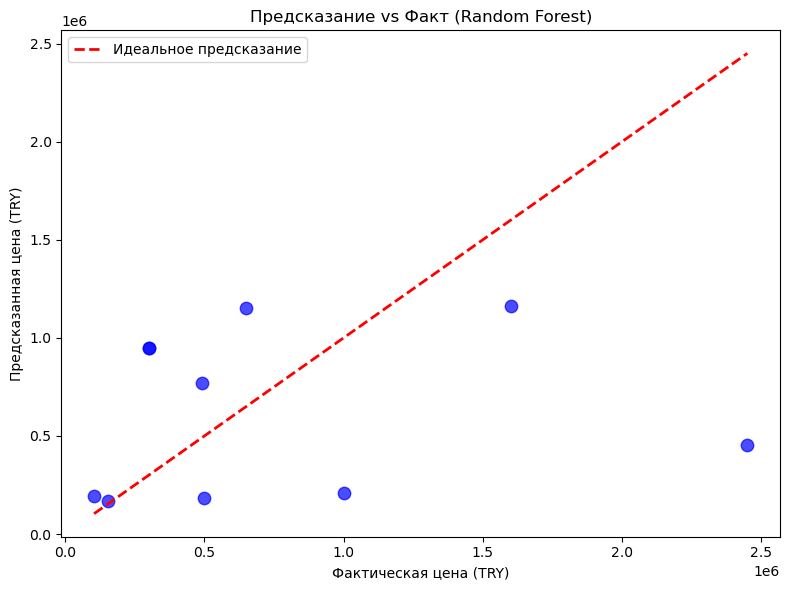

In [53]:
plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.7, color='blue', s=80)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=2, label='Идеальное предсказание')
plt.xlabel('Фактическая цена (TRY)')
plt.ylabel('Предсказанная цена (TRY)')
plt.title('Предсказание vs Факт (Random Forest)')
plt.legend()
plt.tight_layout()
plt.savefig('prediction_vs_actual.png', dpi=150)
plt.show()

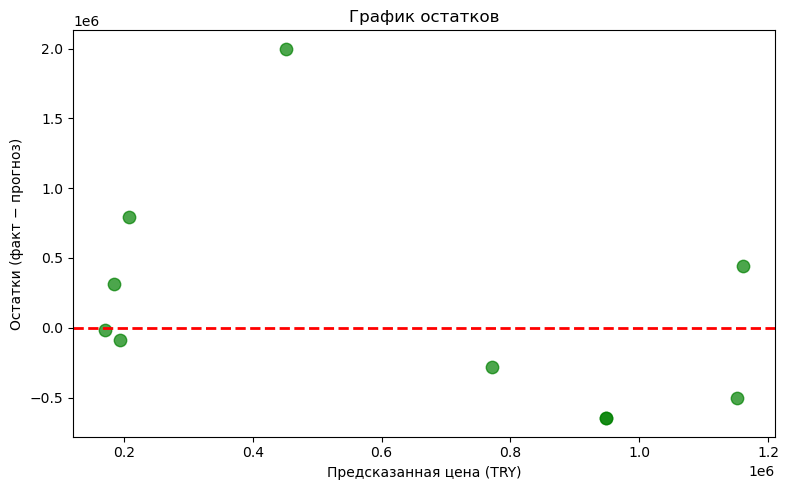

In [54]:
residuals = y_true - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7, color='green', s=80)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Предсказанная цена (TRY)')
plt.ylabel('Остатки (факт − прогноз)')
plt.title('График остатков')
plt.tight_layout()
plt.savefig('residuals_plot.png', dpi=150)
plt.show()

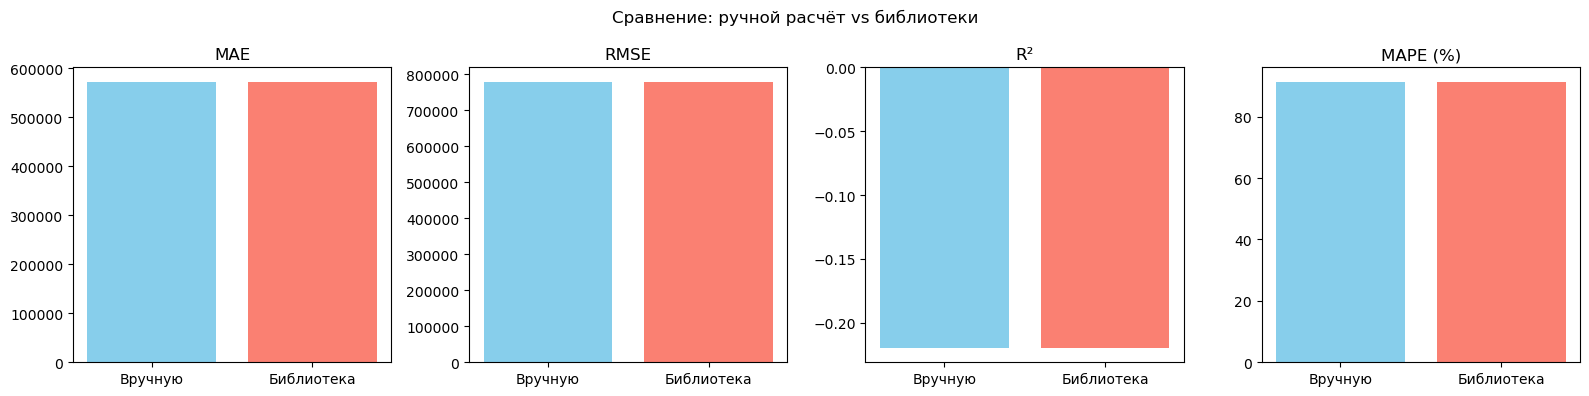

In [55]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
names = ['MAE', 'RMSE', 'R²', 'MAPE (%)']
manual = [mae_manual, rmse_manual, r2_manual, mape_manual]
lib = [mae_lib, rmse_lib, r2_lib, mape_lib]
for i, (n, m, l) in enumerate(zip(names, manual, lib)):
    axes[i].bar(['Вручную', 'Библиотека'], [m, l], color=['skyblue', 'salmon'])
    axes[i].set_title(n)
plt.suptitle('Сравнение: ручной расчёт vs библиотеки')
plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=150)
plt.show()


In [56]:
final_results = results_df.copy()

final_results['ФИО'] = 'Маннанова Л.Р.'
final_results['Группа'] = '23П-1'

In [57]:
data_cols = [c for c in final_results.columns
             if c not in ('predicted_price', 'ФИО', 'Группа')]
final_results = final_results[data_cols + ['predicted_price', 'ФИО', 'Группа']]
final_results

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,...,furnished,heating_type,price,price_currency,actual_price,abs_error,error_percent,predicted_price,ФИО,Группа
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,...,NaN,Fancoil,300000.0,TRY,300000.0,6.484025e+05,216.134167,9.484025e+05,Маннанова Л.Р.,23П-1
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,...,NaN,Yok,1600000.0,TRY,1600000.0,4.387375e+05,27.421094,1.161262e+06,Маннанова Л.Р.,23П-1
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,...,NaN,Fancoil,490000.0,TRY,490000.0,2.811141e+05,57.370231,7.711141e+05,Маннанова Л.Р.,23П-1
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,...,NaN,Yok,103600.0,TRY,103600.0,8.971433e+04,86.596842,1.933143e+05,Маннанова Л.Р.,23П-1
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,...,NaN,Fancoil,300000.0,TRY,300000.0,6.484025e+05,216.134167,9.484025e+05,Маннанова Л.Р.,23П-1
5,100,Konut,Yazlık,1/12/19,NaN,1,46,1,10,9,...,NaN,Fancoil,500000.0,TRY,500000.0,3.157608e+05,63.152152,1.842392e+05,Маннанова Л.Р.,23П-1
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,...,NaN,Fancoil,1000000.0,TRY,1000000.0,7.916194e+05,79.161938,2.083806e+05,Маннанова Л.Р.,23П-1
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,...,NaN,Fancoil,155000.0,TRY,155000.0,1.531084e+04,9.877960,1.703108e+05,Маннанова Л.Р.,23П-1
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,NaN,4,NaN,...,NaN,Kalorifer (Doğalgaz),650000.0,TRY,650000.0,5.011578e+05,77.101196,1.151158e+06,Маннанова Л.Р.,23П-1
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,...,NaN,Fancoil,2450000.0,TRY,2450000.0,1.998135e+06,81.556531,4.518650e+05,Маннанова Л.Р.,23П-1


In [58]:
final_results.to_csv('result_real_estate_samples.csv',
                     index=False, encoding='utf-8-sig')
print("Сохранено:", final_results.shape)

Сохранено: (20, 23)
